# Moon phase check, combined ZTF + ATLAS light curve
Companion to `moon_phase_check.ipynb` (ZTF only) — adds ATLAS forced photometry (fetched via `fetch_atlas_2020sgf.py`, cached in `atlas_lightcurves/`) as two more independent bands (ATLAS-c, ATLAS-o), fit and checked the same way as ZTF g/r. Goal: see whether ATLAS covers epochs ZTF missed (e.g. around full Moon).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.time import Time
from scipy.stats import chi2

from periodicity_tools import (
    get_decline_detections,
    analyze_candidate,
    compute_delta_chi2_curve,
    get_moon_illumination_fraction,
    get_moon_altitude_deg,
)
from atlas_tools import get_atlas_lightcurve_from_file

EPOCH_AFTER_PEAK = 300  # ATLAS has late-time (>300d) host/unrelated-source contamination -- see markdown below
POLY_DEG = 3
N_PHASE_BINS = 30
TNS_FILENAME = "tables/tns_public_objects_until_20250916.csv"

SYNODIC_MONTH = 29.530588853
JD_REF_NEW_MOON = 2451550.26

band_colors = {1: "g", 2: "r", 3: "orange", 4: "blue", 5: "darkorange"}
band_str = {1: "ZTF-g", 2: "ZTF-r", 3: "ZTF-i", 4: "ATLAS-c", 5: "ATLAS-o"}

tns = pd.read_csv(TNS_FILENAME, header=0)

**Data-quality notes (found while building this):**
1. `atlas_tools.py`'s detection filter requires `uJy > 0` (real positive flux), not `abs(uJy)/duJy >= threshold` -- the abs() version (used in `fetch_at_las_t.ipynb`'s `plot_atlas_fp` too) lets significant **negative**-flux subtraction artifacts through as fake "detections" with nonsensical negative magnitudes (found one at m=-17.5). Worth fixing anywhere else that pattern is used.
2. `EPOCH_AFTER_PEAK` is 300 here, not 1000 like the ZTF-only notebook -- ATLAS-o has a handful of isolated points at day 382 and 651 that are *brighter* than anything near peak, almost certainly host-galaxy/unrelated-source contamination long after the real SN faded (ZTF's own baseline ends ~160 d). 1000 d let that corrupt the polynomial fit and period search.

## Load combined bands
ZTF bands via the usual `get_decline_detections` (already peak-onward). ATLAS bands are cut to the same peak-onward window (anchored to the ZTF g-band peak) for the periodicity analysis, so `analyze_candidate`'s poly baseline is fit to the same kind of decline-only data throughout.

In [2]:
def load_band_entries_combined(sn_name, epoch_after_peak=EPOCH_AFTER_PEAK, poly_deg=POLY_DEG,
                                min_det=5):
    discovery_jd = Time(tns.loc[tns["name"] == sn_name, "discoverydate"].iloc[0]).jd

    raw_bands = {}  # fid -> (jd, mag, err), UNCUT (for the raw combined light curve plot)

    decline_points = get_decline_detections(sn_name, epoch_after_peak=epoch_after_peak)
    for fid in [1, 2, 3]:
        band_data = [p for p in decline_points if p.get("fid") == fid and "candid" in p]
        if len(band_data) < min_det:
            continue
        jd = np.array([p["jd"] for p in band_data])
        mag = np.array([p["magpsf"] for p in band_data])
        err = np.array([p["sigmapsf"] for p in band_data])
        order = np.argsort(jd)
        raw_bands[fid] = (jd[order], mag[order], err[order])

    atlas_bands = get_atlas_lightcurve_from_file(sn_name)
    raw_bands.update(atlas_bands)

    if 1 not in raw_bands and 2 not in raw_bands:
        raise ValueError(f"No ZTF g/r data for {sn_name} -- can't anchor the peak epoch")
    peak_jd = raw_bands[1][0][0] if 1 in raw_bands else raw_bands[2][0][0]
    peak_cut_max_jd = peak_jd + epoch_after_peak

    band_entries = []
    for fid, (jd, mag, err) in raw_bands.items():
        sel = (jd >= peak_jd) & (jd <= peak_cut_max_jd)
        if sel.sum() < min_det:
            continue
        jd_cut, mag_cut, err_cut = jd[sel], mag[sel], err[sel]
        days = jd_cut - peak_jd

        res = analyze_candidate(sn_name, days, mag_cut, err_cut, poly_deg=poly_deg)
        residuals = mag_cut - res["poly_model"](days)

        moon_frac = get_moon_illumination_fraction(jd_cut)
        moon_alt = get_moon_altitude_deg(jd_cut)
        moon_up = moon_alt > 0
        lunar_phase = ((jd_cut - JD_REF_NEW_MOON) / SYNODIC_MONTH) % 1.0

        band_entries.append({
            "fid": fid, "jd": jd_cut, "days": days, "mag": mag_cut, "err": err_cut,
            "res": res, "residuals": residuals,
            "moon_frac": moon_frac, "moon_alt": moon_alt, "moon_up": moon_up,
            "lunar_phase": lunar_phase,
        })

    return band_entries, discovery_jd, peak_jd, raw_bands


def print_summary(sn_name, band_entries, discovery_jd):
    print(f"=== {sn_name} (discovery JD {discovery_jd:.2f}) ===")
    for e in band_entries:
        n_up = np.sum(e["moon_up"])
        print(f"  {band_str[e['fid']]}: {len(e['jd'])} points, "
              f"best_period={e['res']['best_period']:.2f} d, "
              f"best_amplitude={e['res']['best_amplitude']:.4f} mag, "
              f"delta_chi2={e['res']['delta_chi2']:.1f} | "
              f"Moon above horizon for {n_up}/{len(e['jd'])} points "
              f"({100 * n_up / len(e['jd']):.0f}%)")

In [3]:
sn_name = "2020sgf"
band_entries, discovery_jd, peak_jd, raw_bands = load_band_entries_combined(sn_name)
print_summary(sn_name, band_entries, discovery_jd)

=== 2020sgf (discovery JD 2459089.95) ===
  ZTF-g: 82 points, best_period=30.17 d, best_amplitude=0.1957 mag, delta_chi2=42.3 | Moon above horizon for 31/82 points (38%)
  ZTF-r: 99 points, best_period=36.92 d, best_amplitude=0.1146 mag, delta_chi2=39.1 | Moon above horizon for 42/99 points (42%)
  ATLAS-c: 72 points, best_period=3.34 d, best_amplitude=0.1139 mag, delta_chi2=19.3 | Moon above horizon for 7/72 points (10%)
  ATLAS-o: 101 points, best_period=32.96 d, best_amplitude=0.1362 mag, delta_chi2=38.2 | Moon above horizon for 74/101 points (73%)


## Periodograms, all bands
Δχ² vs. trial period for each band independently, same `compute_delta_chi2_curve` used everywhere else. Grey lines = single-frequency p-value thresholds; gold line = lunar synodic month.

In [4]:
def plot_periodograms(sn_name, band_entries, poly_deg=POLY_DEG, period_xlim=(3, 100)):
    fig, ax = plt.subplots(figsize=(10, 5))
    for e in band_entries:
        freq, dchi2 = compute_delta_chi2_curve(e["days"], e["mag"], e["err"], poly_deg)
        period = 1 / freq
        ax.plot(period, dchi2, color=band_colors.get(e["fid"], "k"), lw=1.5,
                label=f"{band_str[e['fid']]} (best P={e['res']['best_period']:.1f} d)")

    ax.axhline(chi2.ppf(1 - 1e-4, df=2), color="grey", ls="--", lw=1.2, label=r"$p=10^{-4}$")
    ax.axhline(chi2.ppf(1 - 1e-5, df=2), color="grey", ls=":", lw=1.2, label=r"$p=10^{-5}$")
    ax.axvline(SYNODIC_MONTH, color="goldenrod", ls=":", lw=1.5, label="Lunar synodic month")

    ax.set_xlim(*period_xlim)
    ax.set_xlabel("Period (days)")
    ax.set_ylabel(r"$\Delta\chi^2$")
    ax.set_title(f"{sn_name}: periodograms, all bands")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

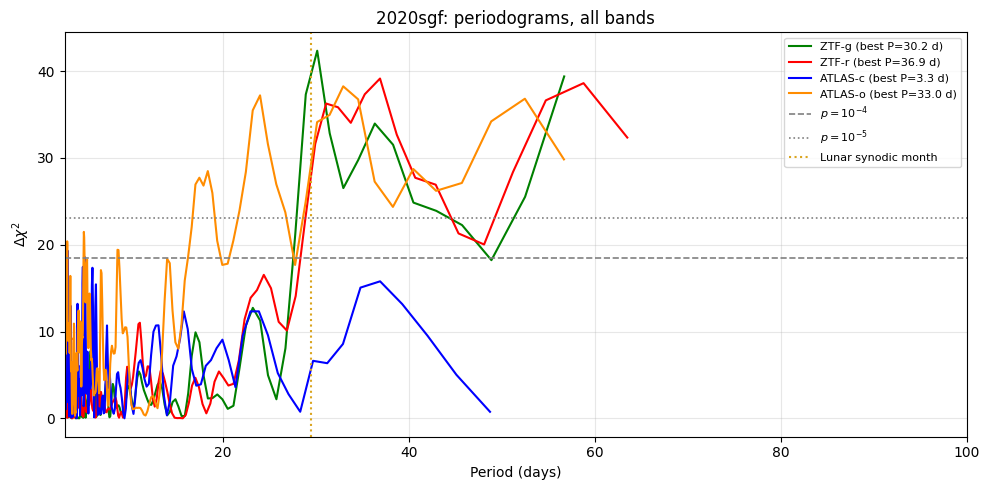

In [5]:
sn_name = "2020sgf"
band_entries, discovery_jd, peak_jd, raw_bands = load_band_entries_combined(sn_name)
plot_periodograms(sn_name, band_entries)

In [6]:
def weighted_bin(x, y, err, bin_edges):
    xs, means, sems = [], [], []
    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        in_bin = (x >= lo) & (x < hi if hi < bin_edges[-1] else x <= hi)
        if not np.any(in_bin):
            continue
        weights = 1.0 / err[in_bin] ** 2
        xs.append(np.average(x[in_bin], weights=weights))
        means.append(np.average(y[in_bin], weights=weights))
        sems.append(np.sqrt(1.0 / np.sum(weights)))
    return np.array(xs), np.array(means), np.array(sems)


def full_moon_days_since(jd0, day_min, day_max):
    jd_min, jd_max = jd0 + day_min, jd0 + day_max
    n_min = int(np.floor((jd_min - JD_REF_NEW_MOON) / SYNODIC_MONTH - 0.5))
    n_max = int(np.ceil((jd_max - JD_REF_NEW_MOON) / SYNODIC_MONTH - 0.5))
    out = []
    for n in range(n_min, n_max + 1):
        fm_jd = JD_REF_NEW_MOON + SYNODIC_MONTH * (n + 0.5)
        if jd_min <= fm_jd <= jd_max:
            out.append(fm_jd - jd0)
    return out

## Phased fit quality
Same right-panel style as `plot_with_phase()` in `periodicity_search.ipynb` (candidate's own best period, weighted-mean-binned residuals, best-fit sinusoid) -- a plain fit-quality check, no Moon coloring.

In [7]:
def plot_phased_fit(sn_name, band_entries, n_bins=N_PHASE_BINS):
    fig, axes = plt.subplots(1, len(band_entries), figsize=(6 * len(band_entries), 4.5), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, e in zip(axes, band_entries):
        color = band_colors.get(e["fid"], "k")
        days, y, err = e["days"], e["residuals"], e["err"]
        period = e["res"]["best_period"]
        pval = e["res"]["p_value_single_freq"]
        A_fit, B_fit = e["res"]["full_params"][-2], e["res"]["full_params"][-1]
        t_mean = np.mean(days)

        phase = (days % period) / period
        phase_double = np.concatenate([phase, phase + 1])
        y_double = np.concatenate([y, y])
        err_double = np.concatenate([err, err])

        ax.errorbar(phase_double, y_double, yerr=err_double, fmt="o", color="0.65",
                    ecolor="0.75", alpha=0.35, ms=4, label="All residuals", zorder=1)

        bx, by, be = weighted_bin(phase_double, y_double, err_double, np.linspace(0, 2, n_bins + 1))
        ax.errorbar(bx, by, yerr=be, fmt="o", color=color, ecolor=color, ms=6,
                    capsize=2, label="Binned residuals", zorder=3)

        phase_model = np.linspace(0, 2, 1000)
        t_model_centered = phase_model * period - t_mean
        omega = 2 * np.pi / period
        sin_model = A_fit * np.sin(omega * t_model_centered) + B_fit * np.cos(omega * t_model_centered)
        ax.plot(phase_model, sin_model, color="black", lw=2, label="Best-fit sinusoid")

        ax.axhline(0, color="black", ls="--", lw=1)
        ax.set_xlim(0, 2)
        ax.set_xlabel("Phase")
        pval_str = f"p-val={pval:.1e}" if pval > 0 else r"p-val <1e-16"
        ax.set_title(f"{sn_name} | {band_str[e['fid']]} | P={period:.1f} d | {pval_str}")
        ax.legend(fontsize=8)

    axes[0].set_ylabel("Residual (mag)")
    plt.tight_layout()
    plt.show()

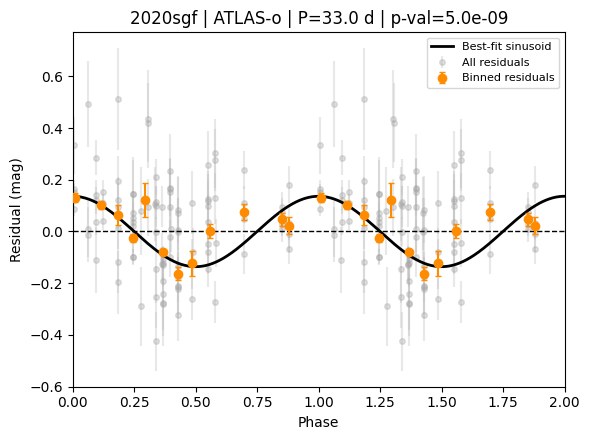

In [8]:
sn_name = "2020sgf"
band_entries, discovery_jd, peak_jd, raw_bands = load_band_entries_combined(sn_name)
atlas_o_only = [e for e in band_entries if e["fid"] == 5]
plot_phased_fit(sn_name, atlas_o_only)

## Combined light curve (all available data, not just the decline window)
Every band's full cached data, on one shared time axis (days since ZTF g-band peak) -- this is the direct "does ATLAS fill ZTF's gaps" view.

In [9]:
def plot_combined_raw_light_curve(sn_name, raw_bands, peak_jd, max_days=350):
    plt.figure(figsize=(11, 5.5))
    for fid, (jd, mag, err) in raw_bands.items():
        days = jd - peak_jd
        sel = (days >= -30) & (days <= max_days)
        n_excluded = (~sel).sum()
        label = f"{band_str[fid]} (N={sel.sum()}"
        label += f", {n_excluded} pts >{max_days}d excluded)" if n_excluded else ")"
        plt.errorbar(days[sel], mag[sel], yerr=err[sel], fmt="o", color=band_colors.get(fid, "k"),
                     ecolor=band_colors.get(fid, "k"), alpha=0.7, ms=4, label=label)
    plt.gca().invert_yaxis()
    plt.xlabel("Days since ZTF g-band peak")
    plt.ylabel("Magnitude")
    plt.title(f"{sn_name}: combined ZTF + ATLAS light curve (decline window)")
    plt.legend()
    plt.tight_layout()
    plt.show()

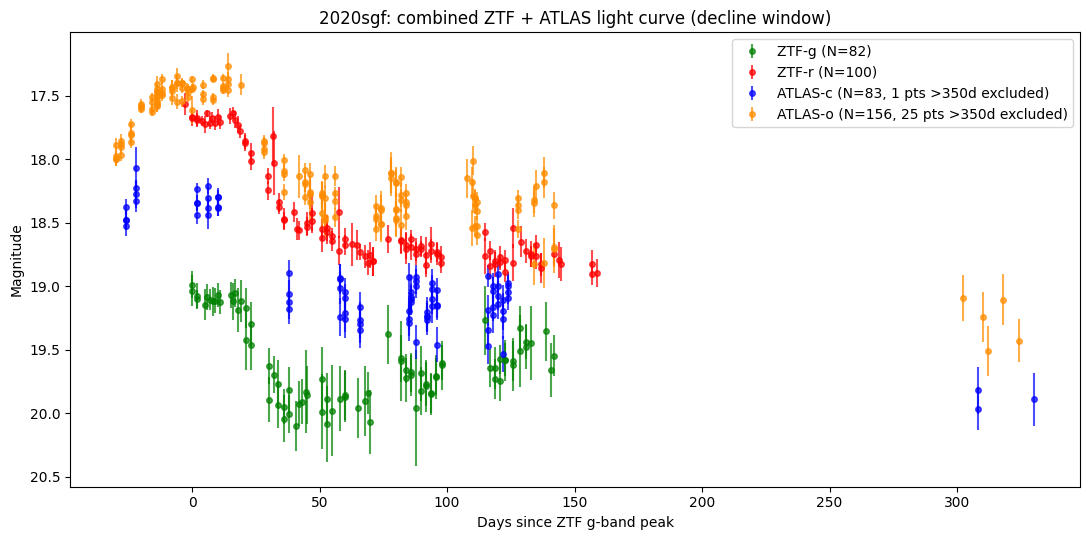

In [10]:
sn_name = "2020sgf"
band_entries, discovery_jd, peak_jd, raw_bands = load_band_entries_combined(sn_name)
plot_combined_raw_light_curve(sn_name, raw_bands, peak_jd)

## Light curve (decline window), full-Moon dates marked
Same peak-onward window used for the periodicity fit, all bands together.

In [11]:
def plot_light_curve_with_moon(sn_name, band_entries):
    fig, axes = plt.subplots(1, len(band_entries), figsize=(6.5 * len(band_entries), 4.5))
    axes = np.atleast_1d(axes)

    for ax, e in zip(axes, band_entries):
        color = band_colors.get(e["fid"], "k")
        days, mag, err = e["days"], e["mag"], e["err"]
        jd0 = e["jd"][0] - days[0]  # = peak_jd, same for every band here
        period = e["res"]["best_period"]
        poly_model, full_model = e["res"]["poly_model"], e["res"]["full_model"]

        ax.errorbar(days, mag, yerr=err, fmt="o", color=color, ecolor=color,
                    alpha=0.8, ms=5, zorder=3, label="Data")

        t_grid = np.linspace(days.min(), days.max(), 1000)
        ax.plot(t_grid, poly_model(t_grid), color="black", ls="--", lw=2, zorder=2, label="Baseline")
        ax.plot(t_grid, full_model(t_grid), color="black", ls="-", lw=2, zorder=2,
                label="Baseline + sinusoid")

        for fm_day in full_moon_days_since(jd0, days.min(), days.max()):
            ax.axvline(fm_day, color="goldenrod", ls=":", lw=1.5, zorder=1)
        ax.plot([], [], color="goldenrod", ls=":", lw=1.5, label="Full Moon")

        ax.invert_yaxis()
        ax.set_xlabel("Days since peak")
        ax.set_ylabel("Magnitude")
        ax.set_title(f"{sn_name} | {band_str[e['fid']]} | P={period:.1f} d")
        ax.legend(fontsize=7)

    plt.tight_layout()
    plt.show()

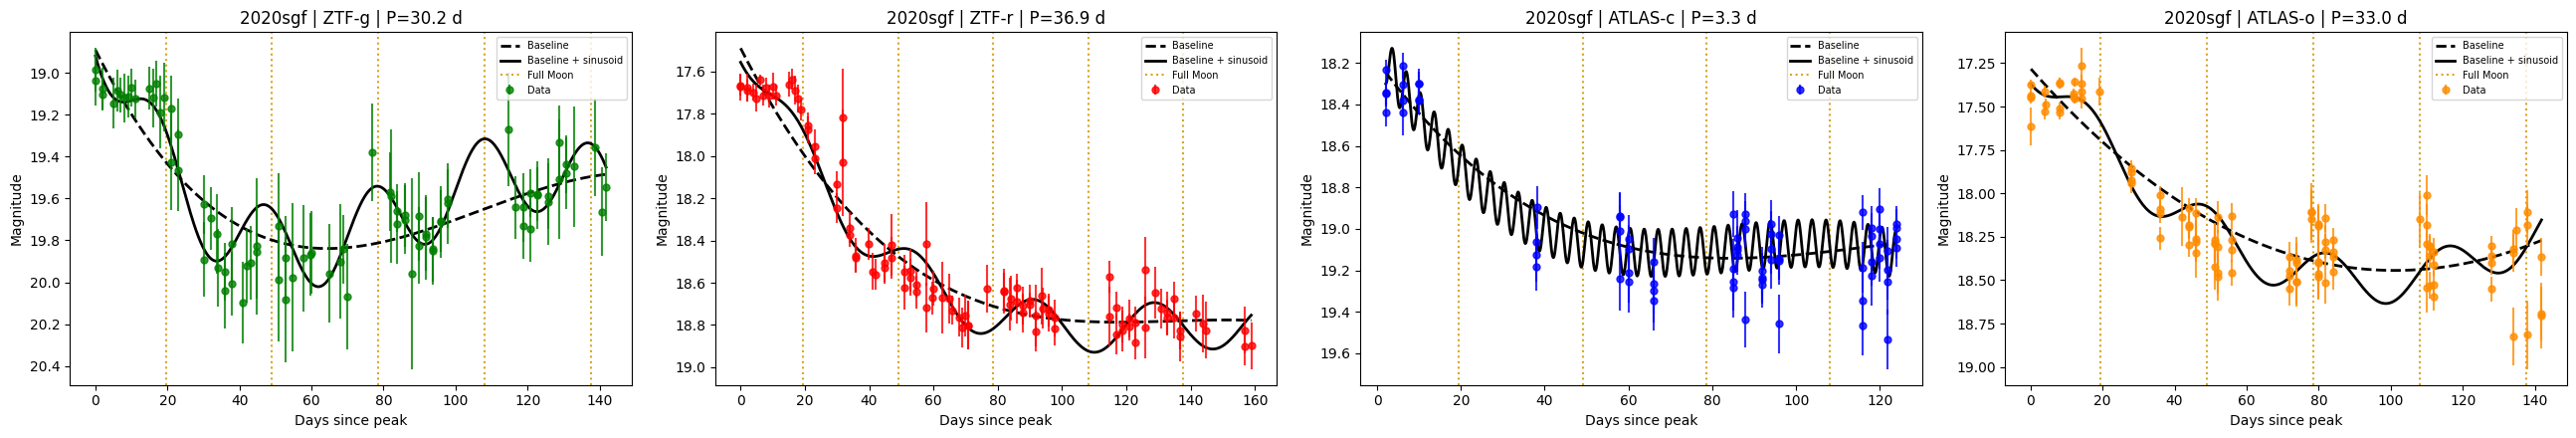

In [12]:
sn_name = "2020sgf"
band_entries, discovery_jd, peak_jd, raw_bands = load_band_entries_combined(sn_name)
plot_light_curve_with_moon(sn_name, band_entries)

## Folded residuals, colored by Moon illumination
The strongest diagnostic from the ZTF-only notebook, now across all 4 bands. Color = mean illumination among moon-up points in that bin; size = # moon-up points behind the color.

In [13]:
def plot_folded_binned_colored(sn_name, band_entries, n_bins=N_PHASE_BINS, save_paths=None):
    fig, axes = plt.subplots(1, len(band_entries), figsize=(6.5 * len(band_entries), 4.5), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, e in zip(axes, band_entries):
        days, y, err = e["days"], e["residuals"], e["err"]
        moon_frac = e["moon_frac"]
        period = e["res"]["best_period"]
        A_fit, B_fit = e["res"]["full_params"][-2], e["res"]["full_params"][-1]
        t_mean = np.mean(days)

        phase = (days % period) / period
        phase_double = np.concatenate([phase, phase + 1])
        y_double = np.concatenate([y, y])
        err_double = np.concatenate([err, err])
        up_double = np.concatenate([e["moon_up"], e["moon_up"]])
        frac_double = np.concatenate([moon_frac, moon_frac])

        ax.errorbar(phase_double, y_double, yerr=err_double, fmt="o", color="0.75",
                    ecolor="0.85", alpha=0.35, ms=4, zorder=1, label="All residuals")

        bin_edges = np.linspace(0, 2, n_bins + 1)
        bx, by, be, b_frac_up, b_n_up = [], [], [], [], []
        for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
            in_bin = (phase_double >= lo) & (phase_double < hi if hi < bin_edges[-1] else phase_double <= hi)
            if not np.any(in_bin):
                continue
            w = 1.0 / err_double[in_bin] ** 2
            bx.append(np.average(phase_double[in_bin], weights=w))
            by.append(np.average(y_double[in_bin], weights=w))
            be.append(np.sqrt(1.0 / np.sum(w)))
            n_up = int(np.sum(up_double[in_bin]))
            b_n_up.append(n_up)
            b_frac_up.append(np.mean(frac_double[in_bin][up_double[in_bin]]) if n_up > 0 else np.nan)

        bx, by, be = np.array(bx), np.array(by), np.array(be)
        b_frac_up, b_n_up = np.array(b_frac_up), np.array(b_n_up)
        has_support = ~np.isnan(b_frac_up)

        ax.errorbar(bx, by, yerr=be, fmt="none", ecolor="black", capsize=2, zorder=2)
        ax.scatter(bx[~has_support], by[~has_support], facecolors="none", edgecolors="0.6",
                   s=50, zorder=3, label="No moon-up point in bin")
        sizes = 35 + 20 * b_n_up[has_support]
        sc = ax.scatter(bx[has_support], by[has_support], c=b_frac_up[has_support],
                         cmap="viridis", vmin=0, vmax=1, s=sizes, edgecolor="black",
                         linewidth=0.8, zorder=4, label="Binned (size = # moon-up pts)")

        phase_model = np.linspace(0, 2, 1000)
        t_model_centered = phase_model * period - t_mean
        omega = 2 * np.pi / period
        sin_model = A_fit * np.sin(omega * t_model_centered) + B_fit * np.cos(omega * t_model_centered)
        ax.plot(phase_model, sin_model, color="black", lw=2, label="Best-fit sinusoid")

        ax.axhline(0, color="black", ls="--", lw=1)
        ax.set_xlim(0, 2)
        ax.set_xlabel("Phase (candidate period)")
        ax.set_title(f"{sn_name} | {band_str[e['fid']]} | P={period:.1f} d")
        ax.legend(fontsize=6)
        plt.colorbar(sc, ax=ax, label="Moon illum., moon-up only")

        r = np.corrcoef(b_frac_up[has_support], by[has_support])[0, 1] if has_support.sum() > 1 else np.nan
        print(f"{sn_name} {band_str[e['fid']]}: correlation (binned residual vs. binned "
              f"moon-up illumination) = {r:.3f} ({np.sum(has_support)}/{len(bx)} bins)")

    axes[0].set_ylabel("Residual (mag)")
    plt.tight_layout()
    if save_paths:
        for path in save_paths:
            plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

2020sgf ZTF-g: correlation (binned residual vs. binned moon-up illumination) = -0.754 (24/30 bins)
2020sgf ZTF-r: correlation (binned residual vs. binned moon-up illumination) = -0.487 (26/30 bins)
2020sgf ATLAS-c: correlation (binned residual vs. binned moon-up illumination) = -1.000 (4/28 bins)
2020sgf ATLAS-o: correlation (binned residual vs. binned moon-up illumination) = -0.426 (24/24 bins)


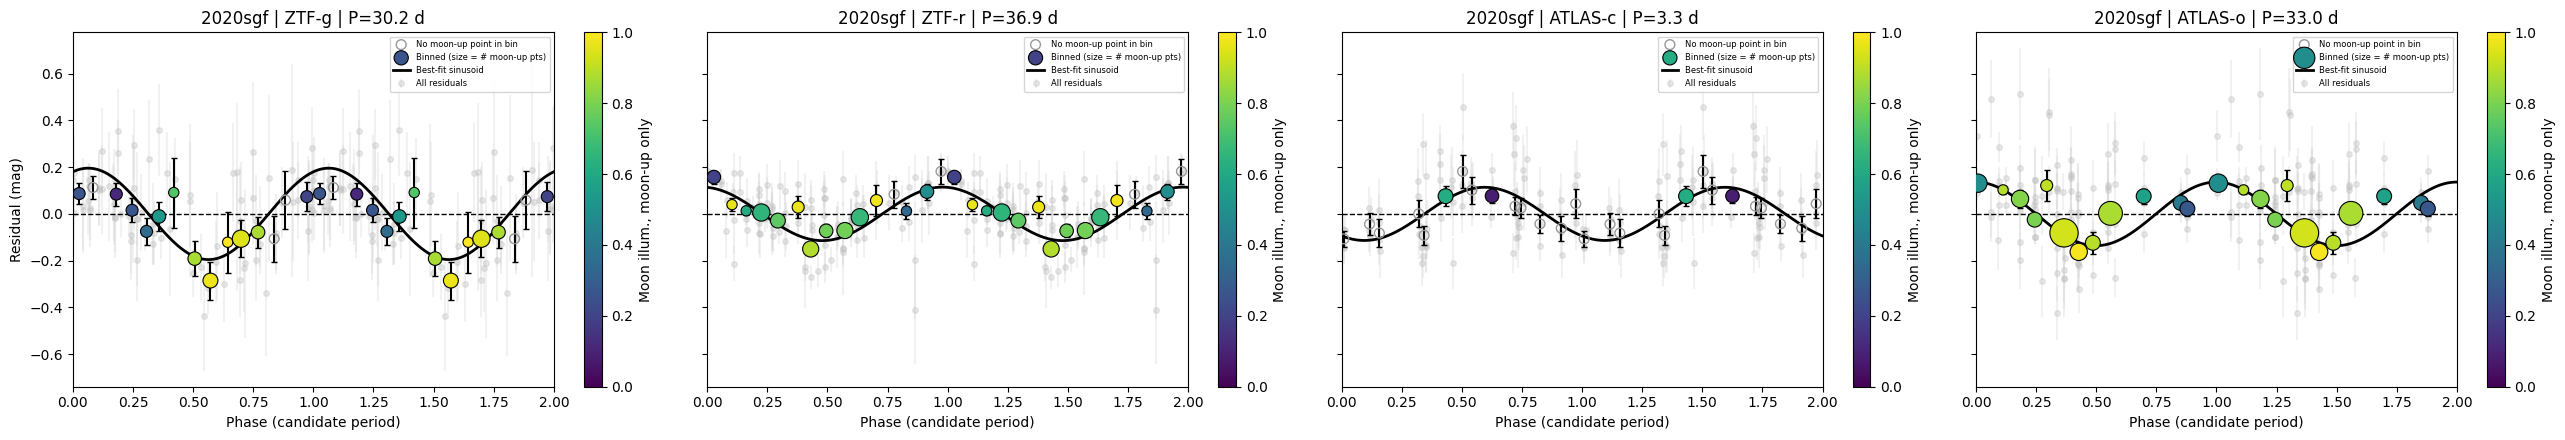

In [14]:
sn_name = "2020sgf"
band_entries, discovery_jd, peak_jd, raw_bands = load_band_entries_combined(sn_name)
plot_folded_binned_colored(sn_name, band_entries)

2020sgf ZTF-g: correlation (binned residual vs. binned moon-up illumination) = -0.754 (24/30 bins)
2020sgf ZTF-r: correlation (binned residual vs. binned moon-up illumination) = -0.487 (26/30 bins)
2020sgf ATLAS-o: correlation (binned residual vs. binned moon-up illumination) = -0.426 (24/24 bins)


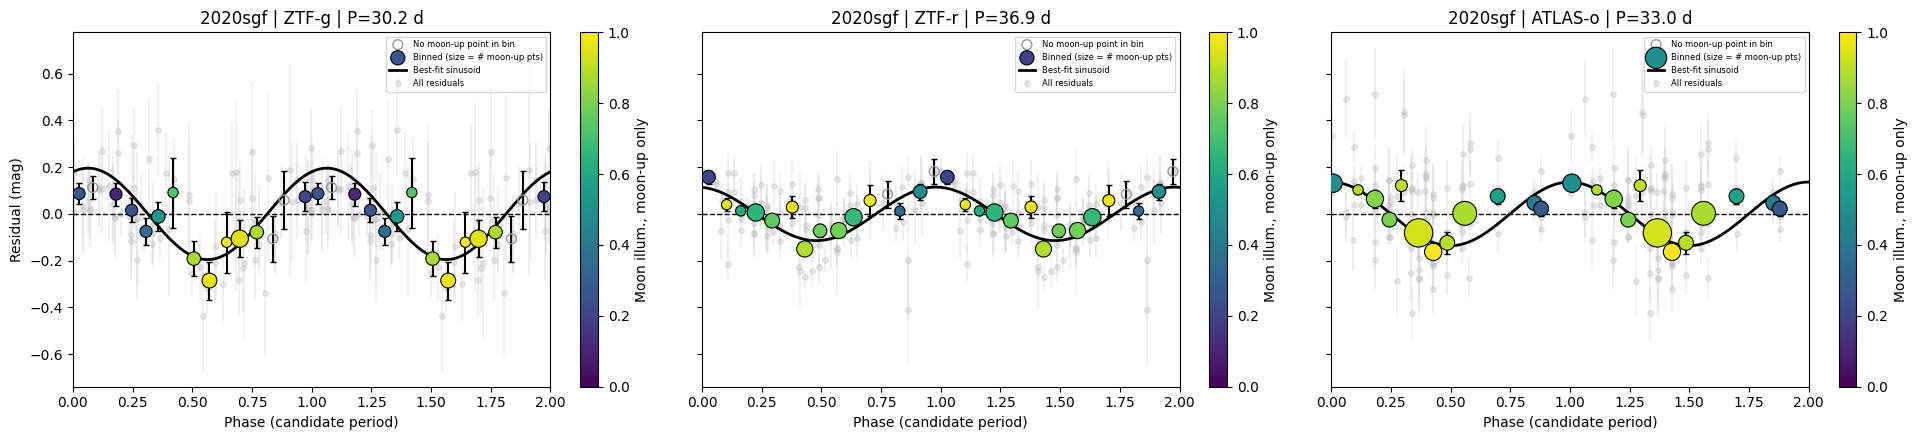

In [15]:
# Paper figure: ZTF-g, ZTF-r, and ATLAS-o only (ATLAS-c excluded -- too few
# moon-up points to be informative, see the significance section above).
sn_name = "2020sgf"
band_entries, discovery_jd, peak_jd, raw_bands = load_band_entries_combined(sn_name)
paper_bands = [e for e in band_entries if e["fid"] in (1, 2, 5)]
plot_folded_binned_colored(
    sn_name, paper_bands,
    save_paths=["Figures/2020sgf_moon_phase_fold.pdf", "Overleaf/2020sgf_moon_phase_fold.pdf"],
)

## Significance of residuals vs. Moon illumination correlation
Same as the ZTF-only notebook: significance = r / (1/sqrt(N)) = r*sqrt(N), plus a bootstrap shuffle test (shuffle residuals against Moon illumination 2000 times, see where the real value falls in that null distribution).

In [16]:
def print_illum_correlation_significance(sn_name, band_entries):
    for e in band_entries:
        up = e["moon_up"]
        r = np.corrcoef(e["moon_frac"][up], e["residuals"][up])[0, 1]
        n = int(np.sum(up))
        significance = r * np.sqrt(n)
        print(f"{sn_name} {band_str[e['fid']]}: r={r:.3f} (N={n}), "
              f"r / (1/sqrt(N)) = {significance:.2f}")


def bootstrap_illum_correlation(sn_name, band_entries, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(1, len(band_entries), figsize=(5.5 * len(band_entries), 4), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, e in zip(axes, band_entries):
        up = e["moon_up"]
        x = e["moon_frac"][up]
        y = e["residuals"][up]
        n = len(x)
        if n < 4:
            ax.set_title(f"{sn_name} | {band_str[e['fid']]} (N={n}, too few)")
            continue

        r_real = np.corrcoef(x, y)[0, 1]
        sig_real = r_real * np.sqrt(n)

        boot_sig = np.empty(n_boot)
        for i in range(n_boot):
            y_shuffled = rng.permutation(y)
            r_b = np.corrcoef(x, y_shuffled)[0, 1]
            boot_sig[i] = r_b * np.sqrt(n)

        p_empirical = np.mean(np.abs(boot_sig) >= np.abs(sig_real))

        ax.hist(boot_sig, bins=40, color="0.75", edgecolor="0.4",
                label="Shuffled residuals\n(no real pairing)")
        ax.axvline(sig_real, color="crimson", lw=2, label=f"Real data ({sig_real:.2f})")
        ax.set_xlabel("Significance = r / (1/sqrt(N))")
        ax.set_title(f"{sn_name} | {band_str[e['fid']]}")
        ax.legend(fontsize=7)

        print(f"{sn_name} {band_str[e['fid']]}: real significance={sig_real:.2f}. "
              f"Out of {n_boot} random shuffles, {100 * p_empirical:.2f}% were at "
              f"least this extreme.")

    axes[0].set_ylabel("Count (shuffles)")
    plt.tight_layout()
    plt.show()

2020sgf ZTF-g: r=-0.448 (N=31), r / (1/sqrt(N)) = -2.49
2020sgf ZTF-r: r=-0.538 (N=42), r / (1/sqrt(N)) = -3.49
2020sgf ATLAS-c: r=-0.422 (N=7), r / (1/sqrt(N)) = -1.12
2020sgf ATLAS-o: r=-0.259 (N=74), r / (1/sqrt(N)) = -2.23
2020sgf ZTF-g: real significance=-2.49. Out of 2000 random shuffles, 1.25% were at least this extreme.
2020sgf ZTF-r: real significance=-3.49. Out of 2000 random shuffles, 0.00% were at least this extreme.
2020sgf ATLAS-c: real significance=-1.12. Out of 2000 random shuffles, 43.95% were at least this extreme.
2020sgf ATLAS-o: real significance=-2.23. Out of 2000 random shuffles, 2.95% were at least this extreme.


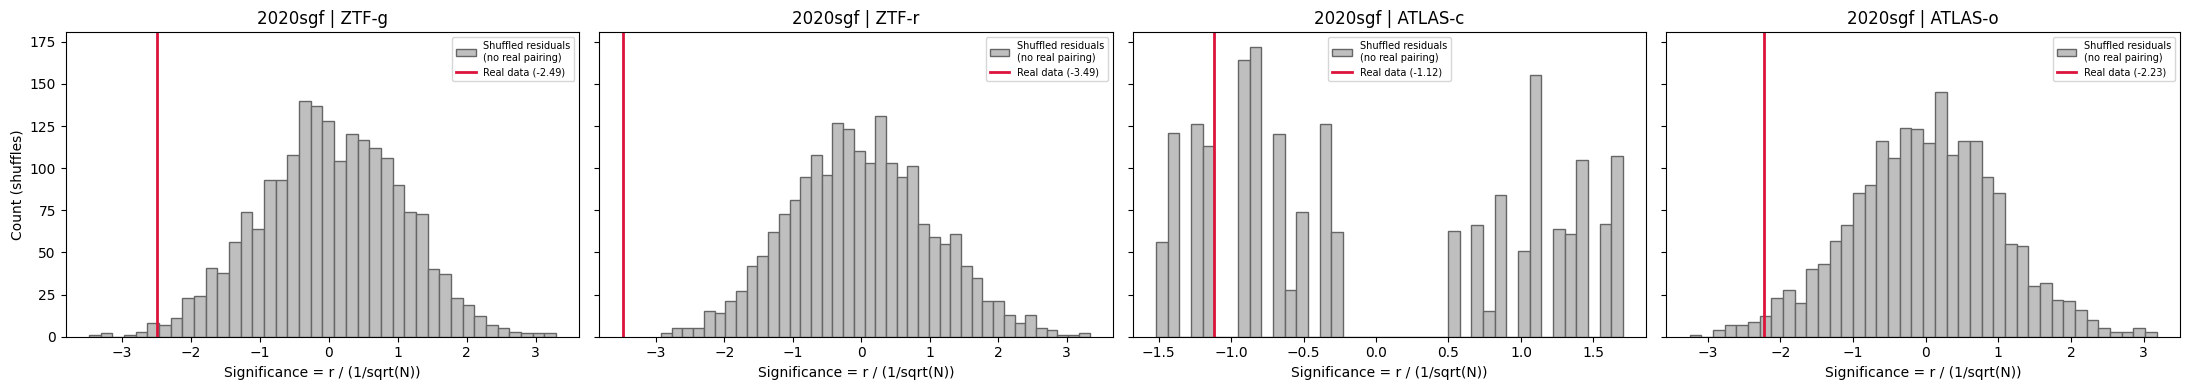

In [17]:
sn_name = "2020sgf"
band_entries, discovery_jd, peak_jd, raw_bands = load_band_entries_combined(sn_name)
print_illum_correlation_significance(sn_name, band_entries)
bootstrap_illum_correlation(sn_name, band_entries)